Following mostly the online documentation of `SageMath`, this notebook introduces the construction of line arrangements.

# 1. A Rectangular Grid

We work with rational numbers, over `QQ` and the equations for the lines are in the variables `x` and `y`.

In [1]:
H.<x,y> = HyperplaneArrangements(QQ)

In [2]:
H

Hyperplane arrangements in 2-dimensional linear space over Rational Field with coordinates x, y

Then the four lines in the rectangular grid are

1. $x=0$, the vertical axis,

2. $y=0$, the horizontal axis,

3. $x=1$, a line parallel to the vertical axis, and

4. $y=1$, a line parallel to the horizontal axis.

Symbolically, this arrangement of four lines can be defined quickly.

In [3]:
box = x | y | x-1 | y-1

In [4]:
box

Arrangement <y - 1 | y | x - 1 | x>

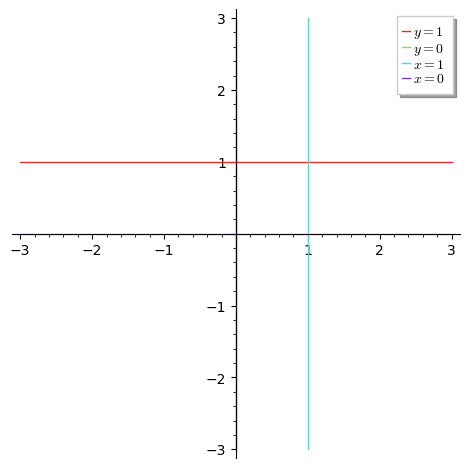

In [5]:
box.plot()

The plot corresponds to what we defined before.

# 2. The Regions of an Arrangement

The `box` is a simple example.

In [6]:
box.n_regions()

9

In [7]:
box.n_bounded_regions()

1

The arrangement defined by `box` has nine regions in total, where one is bounded.

In [8]:
box.bounded_regions()

(A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 4 vertices,)

In [9]:
box.hyperplanes()

(Hyperplane 0*x + y - 1,
 Hyperplane 0*x + y + 0,
 Hyperplane x + 0*y - 1,
 Hyperplane x + 0*y + 0)

In [10]:
box.vertices()

((0, 0), (0, 1), (1, 0), (1, 1))

In [11]:
box.regions()

(A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 1 vertex and 2 rays,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 2 vertices and 1 ray,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 1 vertex and 2 rays,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 2 vertices and 1 ray,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 4 vertices,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 2 vertices and 1 ray,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 1 vertex and 2 rays,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 2 vertices and 1 ray,
 A 2-dimensional polyhedron in QQ^2 defined as the convex hull of 1 vertex and 2 rays)

Because we have parallel lines, we have fewer vertices than expected.

# 3. A Random Arrangement of Lines

Let us generate `n` random lines.

In [12]:
n = 5

While we could continue working over the rational numbers, a random rational number does often not look all that random.  For random arrangements of lines, we work over the field of floating-point numbers.

In [13]:
R.<X, Y> = HyperplaneArrangements(RR)

In [14]:
R

Hyperplane arrangements in 2-dimensional linear space over Real Field with 53 bits of precision with coordinates X, Y

In [15]:
RR.random_element()

-0.648977668265286

In [16]:
r = [RR.random_element()*x + RR.random_element()*y + RR.random_element() for _ in range(n)]

In [17]:
for h in r:
    print(h)

Hyperplane -0.285553458027533*x - 0.251568919458398*y - 0.589199312701633
Hyperplane 0.673322276196483*x + 0.544335533355384*y + 0.297305198262567
Hyperplane 0.646075039714467*x - 0.430541812689349*y + 0.855151588776655
Hyperplane -0.530537697107021*x - 0.139101935461643*y + 0.803374773353743
Hyperplane -0.521295278193191*x + 0.719319115444992*y + 0.635642144341222


In [18]:
L = R(r)

In [19]:
L

Arrangement of 5 hyperplanes of dimension 2 and rank 2

In [20]:
L.hyperplanes()

(Hyperplane -1.00000000000000*X - 0.880987123028090*Y - 2.06335905287767,
 Hyperplane -1.00000000000000*X - 0.262190483767985*Y + 1.51426520251903,
 Hyperplane -1.00000000000000*X + 1.37986884887611*Y + 1.21935143273186,
 Hyperplane 1.00000000000000*X - 0.666395985332643*Y + 1.32361031801289,
 Hyperplane 1.00000000000000*X + 0.808432384608260*Y + 0.441549624560186)

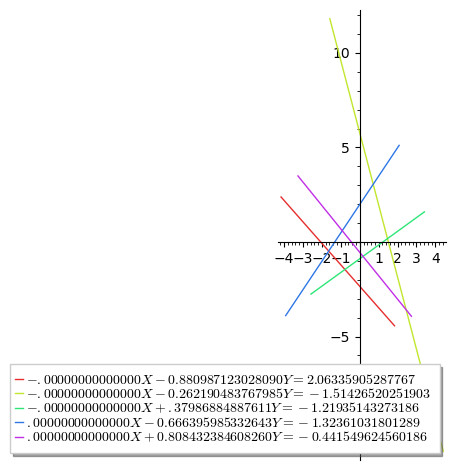

In [21]:
L.plot()

Unfortunately, computing the vertices with floating-point arithmetic does not work well.

In [22]:
r[0].coefficients()

[-0.589199312701633, -0.285553458027533, -0.251568919458398]

In [23]:
qr0 = [QQ(c) for c in r[0].coefficients()]
qr0

[-118153217/200531831, -38349041/134297239, -47795698/189990473]

In [24]:
qqc = [[QQ(c) for c in h.coefficients()] for h in r]
qqc

[[-118153217/200531831, -38349041/134297239, -47795698/189990473],
 [53124989/178688396, 30086909/44684262, 54613214/100330055],
 [17732142/20735671, 75114654/116263049, -106224113/246721944],
 [214997575/267618031, -26538927/50022698, -28325776/203633227],
 [67007186/105416525, -28794352/55236165, 113845497/158268416]]

In [25]:
qhr = []
for c in qqc:
    h = c[0]*x + c[1]*y + c[2]
    qhr.append(h)

In [26]:
qhr

[Hyperplane -118153217/200531831*x - 38349041/134297239*y - 47795698/189990473,
 Hyperplane 53124989/178688396*x + 30086909/44684262*y + 54613214/100330055,
 Hyperplane 17732142/20735671*x + 75114654/116263049*y - 106224113/246721944,
 Hyperplane 214997575/267618031*x - 26538927/50022698*y - 28325776/203633227,
 Hyperplane 67007186/105416525*x - 28794352/55236165*y + 113845497/158268416]

In [27]:
QL = H(qhr)
QL

Arrangement of 5 hyperplanes of dimension 2 and rank 2

In [28]:
v = QL.vertices()
v

((-17730540129456722191015773744031740488980741937/8476339542784488505455809938999608948093402912, 29116924500918396808168131881543258786684015713/8476339542784488505455809938999608948093402912),
 (-270024421740890695630854029049435195014838909/204946120169210022302285927214913853922285568, -3657944771876687693424894162486371372780961/16137489777103151362384718678339673537187840),
 (-317382374043455492603347169229320312262774770395/460831853142144173116903617727447050436864968704, 248886866206969769898301276530102227229428792619/460831853142144173116903617727447050436864968704),
 (-1852023596873692503884290474849131978262495/6600987099826208934893919270336650149619712, 289993021087309517807598696153552661399291981/279441787225976178243842582444251523000567808),
 (-30437524124130055441410445810745288649269056408/108981315585605185292335441710580442414651927465, -2133267071058996885798180349746989679745930128/3113751873874433865495298334588012640418626499),
 (-130757007282032100385857994

In [29]:
len(v)

10

The number of vertices of a random arrangement of lines should always be the same.

In [30]:
QL.n_regions()

16

And also the number of regions should always be the same for an arrangement of random lines.

# 4. An Orchard

Consider nine points arranged in rows of three, called an *orchard*.  According to Coxeter (Introduction to Geometry, Wiley), it was probably the investigation of such configurations that led Sylvester to his problem on the collinearity of point configurations.

In [31]:
tenlines = [
    x, y + 1, y, y - 1, x + y, x - y,
    2*x - y + 1, 2*x + y - 1,
    -2*x + y + 1, -2*x - y - 1]

In [32]:
orchard = R(tenlines)

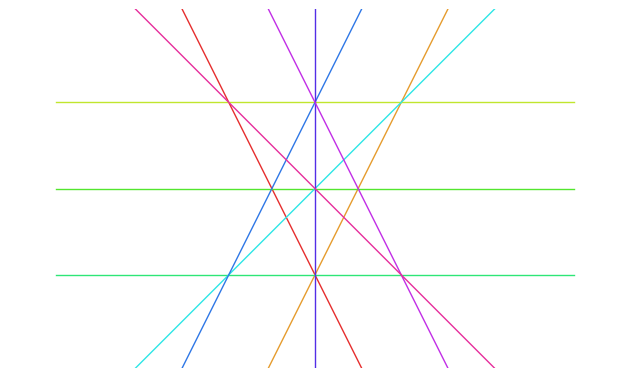

In [33]:
orchard.plot(axes=False,xmin=-2,xmax=2,ymin=-2,ymax=2,hyperplane_legend=False)

In [34]:
orchard.vertices()

((-1.00000000000000, -1.00000000000000),
 (-1.00000000000000, 1.00000000000000),
 (-0.500000000000000, -0.000000000000000),
 (-0.333333333333333, 0.333333333333333),
 (-0.333333333333333, -0.333333333333333),
 (0.000000000000000, -1.00000000000000),
 (-0.000000000000000, -0.000000000000000),
 (0.000000000000000, 1.00000000000000),
 (0.333333333333333, 0.333333333333333),
 (0.333333333333333, -0.333333333333333),
 (0.500000000000000, -0.000000000000000),
 (1.00000000000000, -1.00000000000000),
 (1.00000000000000, 1.00000000000000))

In [35]:
orchard.hyperplanes()

(Hyperplane -1.00000000000000*X - 0.500000000000000*Y - 0.500000000000000,
 Hyperplane -1.00000000000000*X + 0.500000000000000*Y + 0.500000000000000,
 Hyperplane 0.000000000000000*X + 1.00000000000000*Y - 1.00000000000000,
 Hyperplane 0.000000000000000*X + 1.00000000000000*Y + 0.000000000000000,
 Hyperplane 0.000000000000000*X + 1.00000000000000*Y + 1.00000000000000,
 Hyperplane 1.00000000000000*X - 1.00000000000000*Y + 0.000000000000000,
 Hyperplane 1.00000000000000*X - 0.500000000000000*Y + 0.500000000000000,
 Hyperplane 1.00000000000000*X + 0.000000000000000*Y + 0.000000000000000,
 Hyperplane 1.00000000000000*X + 0.500000000000000*Y - 0.500000000000000,
 Hyperplane 1.00000000000000*X + 1.00000000000000*Y + 0.000000000000000)

In [36]:
orchard.n_regions()

36